# Early Academic Risk Prediction and Student Support System
## Notebook 02: Exploratory Data Analysis (EDA)

---

### Project Context & Business Goal
* **Objective:** Predict whether a student is academically at risk at the **Day 30** mark so tutors can deliver timely interventions.
* **Eligible Population:** **27,373 students** actively enrolled at Day 30.
* **Target Definition:**
  *   * 1 = At Risk (Students who subsequently **Fail** or withdraw after Day 30): 11,988 students (43.79%).

### Critical Methodological Rule: Zero Data Leakage
In an operational early warning system, predictions are made at the end of **Day 30**. Therefore, all predictive features analyzed in this notebook must be calculated strictly from information available **on or before Day 30** (date <= 30 and date_submitted <= 30).

### Notebook Sections
1. **Project Introduction to EDA**
2. **Import Libraries**
3. **Load Required Datasets**
4. **Create the Day 30 Eligible Cohort**
5. **Demographic Analysis**
6. **VLE Online Engagement Analysis (Day <= 30)**
7. **Early Assessment Analysis (Submission Date <= 30)**
8. **Relationship Between Early Indicators and Academic Risk**
9. **Missing Values and Preprocessing Guidance**
10. **EDA Summary and Next Steps**


---
### Section 1: Project Introduction to EDA

#### 1. What are we doing?
We introduce Exploratory Data Analysis (EDA), explain why it is essential for a data science project, and outline the specific questions we aim to answer using the OULAD dataset.

#### 2. Why are we doing it?
EDA is the foundation of any machine learning project. Before writing feature engineering code or fitting models, we must understand the underlying distributions, patterns, and relationships in our data. EDA allows us to:
1. Verify our target cohort and distribution.
2. Uncover which demographic factors correlate with academic difficulty.
3. Test whether early online learning habits (clicks, active days) differentiate successful students from at-risk students.
4. Discover data quality challenges (such as missing values or zero-click students) so we can handle them properly during preprocessing.


---
### Section 2: Import Libraries

#### 1. What are we doing?
We import the standard data science and visualization libraries: pandas, 
umpy, matplotlib.pyplot, seaborn, and os.

#### 2. Why are we doing it?
Using only standard, beginner-friendly libraries keeps our workflow transparent, clean, and easily reproducible.


In [1]:
# Import core libraries for data analysis and visualization
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
%matplotlib inline
sns.set_theme(style='whitegrid')

print("All libraries imported successfully!")


C:\Users\vhres\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\vhres\AppData\Local\Temp\matplotlib-4zu02pd6 because there was an issue with the default path (C:\Users\vhres\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


All libraries imported successfully!


#### 4. Expected Output
A success message confirming all libraries are loaded without errors.

#### 5. Interpretation of Results
The environment is initialized and ready for data exploration.


---
### Section 3: Load the Required Datasets

#### 1. What are we doing?
We locate the raw OULAD CSV files and load the tables required for EDA. For the large studentVle.csv file (10.65M rows), we use usecols to load only the specific columns needed for our analysis.

#### 2. Why are we doing it?
Loading only the required columns from studentVle.csv (code_module, code_presentation, id_student, id_site, date, sum_click) saves memory and keeps data processing fast and efficient. We also supply 
a_values='?' so missing values are converted into proper NaN values.


In [2]:
# Resolve dataset directory path safely
if os.path.exists('data/raw/oulad'):
    data_path = 'data/raw/oulad/'
elif os.path.exists('../data/raw/oulad'):
    data_path = '../data/raw/oulad/'
else:
    data_path = 'D:/STD_SUPPORT_project/data/raw/oulad/'

print(f"Loading datasets from: {data_path}")


Loading datasets from: ../data/raw/oulad/


In [3]:
# Load student demographic and registration tables
student_info = pd.read_csv(data_path + 'studentInfo.csv', na_values='?')
student_reg = pd.read_csv(data_path + 'studentRegistration.csv', na_values='?')

# Load assessment metadata and student submission records
assessments = pd.read_csv(data_path + 'assessments.csv', na_values='?')
student_assessment = pd.read_csv(data_path + 'studentAssessment.csv', na_values='?')

# Load student VLE clickstream with only required columns
vle_cols = ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']
student_vle = pd.read_csv(data_path + 'studentVle.csv', usecols=vle_cols)

print("Datasets loaded successfully:")
print(f"- student_info: {student_info.shape}")
print(f"- student_reg: {student_reg.shape}")
print(f"- assessments: {assessments.shape}")
print(f"- student_assessment: {student_assessment.shape}")
print(f"- student_vle: {student_vle.shape}")


Datasets loaded successfully:
- student_info: (32593, 12)
- student_reg: (32593, 5)
- assessments: (206, 6)
- student_assessment: (173912, 5)
- student_vle: (10655280, 6)


#### 4. Expected Output
Confirmation messages displaying the shapes of all loaded datasets, including student_vle with 10,655,280 rows and 6 columns.

#### 5. Interpretation of Results
All data tables are loaded into memory and ready for cohort construction and exploration.


---
### Section 4: Create the Day 30 Eligible Cohort

#### 1. What are we doing?
We reproduce the exact Day 30 cohort definition established in Notebook 01:
1. Merge student_info with student_reg using the composite key ['code_module', 'code_presentation', 'id_student'].
2. Exclude students who unregistered on or before Day 30 (date_unregistration <= 30).
3. Exclude Withdrawn students with missing unregistration dates (93 ambiguous records).
4. Create the binary 	arget column (1 = At Risk, 5. Validate that the cohort size and class distribution match Notebook 01.

#### 2. Why are we doing it?
To prevent data leakage and align with our real-world early warning objective, our analysis must strictly evaluate students who are actively enrolled at Day 30.


In [4]:
# 1. Merge student_info with student_reg
merged_students = pd.merge(
    student_info,
    student_reg[['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']],
    on=['code_module', 'code_presentation', 'id_student'],
    how='left'
)

# 2. Identify students who unregistered on or before Day 30
is_early_unreg = (merged_students['date_unregistration'].notnull()) & (merged_students['date_unregistration'] <= 30)

# 3. Identify the 93 Withdrawn students with missing unregistration dates
is_withdrawn_unrecorded = (merged_students['final_result'] == 'Withdrawn') & (merged_students['date_unregistration'].isnull())

# 4. Filter to active Day 30 cohort
cohort = merged_students[~is_early_unreg & ~is_withdrawn_unrecorded].copy()

# 5. Define binary target variable
# 0 = Not At Risk (Pass or Distinction)
# 1 = At Risk (Fail or Withdrawn after Day 30)
cohort['target'] = cohort['final_result'].apply(lambda x: 1 if x in ['Fail', 'Withdrawn'] else 0)

# Display cohort validation summary
target_counts = cohort['target'].value_counts()
target_percents = (cohort['target'].value_counts(normalize=True) * 100).round(2)

cohort_summary = pd.DataFrame({
    'Target Class': [0, 1],
    'Outcome Description': ['Not At Risk (Pass / Distinction)', 'At Risk (Fail / Post-Day 30 Withdrawn)'],
    'Student Count': [target_counts[0], target_counts[1]],
    'Percentage (%)': [target_percents[0], target_percents[1]]
})

print(f"Total Eligible Population at Day 30: {len(cohort):,}")
cohort_summary


Total Eligible Population at Day 30: 27,373


,Target Class,Outcome Description,Student Count,Percentage (%)
0,0,Not At Risk (Pass / Distinction),15385,56.21
1,1,At Risk (Fail / Post-Day 30 Withdrawn),11988,43.79


#### 4. Expected Output
* Total eligible population: **27,373 students**
* Target = 0 (Not At Risk): **15,385 students (56.21%)**
* Target = 1 (At Risk): **11,988 students (43.79%)**

#### 5. Interpretation of Results
The cohort count and class percentages match Notebook 01. The dataset contains 27,373 active student enrollments at Day 30, with a balanced 56.2% vs 43.8% target distribution.


---
### Section 5: Demographic Analysis

#### 1. What are we doing?
We analyze student demographic characteristics (gender, highest_education, ge_band, disability, 
um_of_prev_attempts, and studied_credits) and examine how academic risk varies across different student groups.

#### 2. Why are we doing it?
Demographic variables provide the baseline profile of each student upon enrollment. Understanding these patterns helps educators identify student populations who may face structural hurdles or require targeted support.


In [5]:
# Academic risk rate by Gender
gender_risk = cohort.groupby('gender')['target'].agg(['count', 'mean']).reset_index()
gender_risk.columns = ['Gender', 'Student Count', 'Risk Rate']
gender_risk['Risk Rate (%)'] = (gender_risk['Risk Rate'] * 100).round(2)
gender_risk


,Gender,Student Count,Risk Rate,Risk Rate (%)
0,F,12291,0.419982,42.00
1,M,15082,0.452592,45.26


In [6]:
# Academic risk rate by Highest Education Level
education_risk = cohort.groupby('highest_education')['target'].agg(['count', 'mean']).reset_index()
education_risk.columns = ['Highest Education', 'Student Count', 'Risk Rate']
education_risk['Risk Rate (%)'] = (education_risk['Risk Rate'] * 100).round(2)
education_risk = education_risk.sort_values(by='Risk Rate (%)', ascending=False)
education_risk


,Highest Education,Student Count,Risk Rate,Risk Rate (%)
3,No Formal quals,260,0.603846,60.38
2,Lower Than A Level,10706,0.522511,52.25
0,A Level or Equivalent,11989,0.390441,39.04
1,HE Qualification,4131,0.356814,35.68
4,Post Graduate Qualification,287,0.285714,28.57


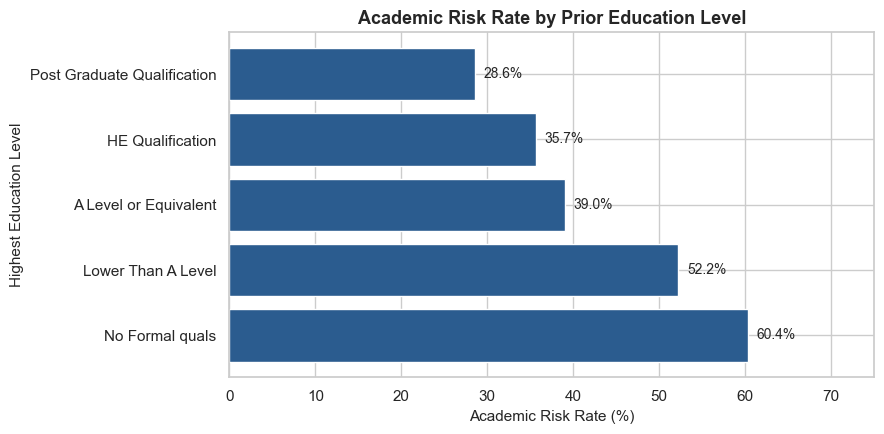

In [7]:
# Visualize Risk Rate by Education Level
plt.figure(figsize=(9, 4.5))
bars = plt.barh(education_risk['Highest Education'], education_risk['Risk Rate (%)'], color='#2b5c8f')
plt.title('Academic Risk Rate by Prior Education Level', fontsize=13, fontweight='bold')
plt.xlabel('Academic Risk Rate (%)', fontsize=11)
plt.ylabel('Highest Education Level', fontsize=11)
plt.xlim(0, 75)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height() / 2., f'{width:.1f}%', ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()


In [8]:
# Academic risk rate by Number of Previous Attempts
prev_attempts_risk = cohort.groupby('num_of_prev_attempts')['target'].agg(['count', 'mean']).reset_index()
prev_attempts_risk.columns = ['Prior Attempts', 'Student Count', 'Risk Rate']
prev_attempts_risk['Risk Rate (%)'] = (prev_attempts_risk['Risk Rate'] * 100).round(2)
prev_attempts_risk


,Prior Attempts,Student Count,Risk Rate,Risk Rate (%)
0,0,23919,0.414482,41.45
1,1,2744,0.584548,58.45
2,2,554,0.653430,65.34
3,3,111,0.711712,71.17
4,4,31,0.580645,58.06
5,5,11,0.818182,81.82
6,6,3,0.666667,66.67


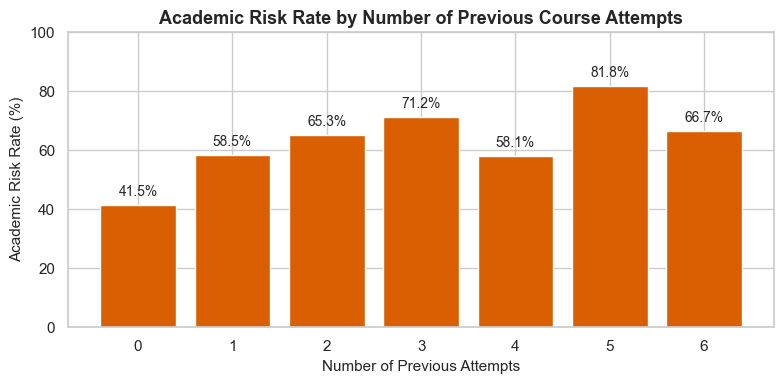

In [9]:
# Visualize Risk Rate by Number of Previous Attempts
plt.figure(figsize=(8, 4))
bars = plt.bar(prev_attempts_risk['Prior Attempts'], prev_attempts_risk['Risk Rate (%)'], color='#d95f02')
plt.title('Academic Risk Rate by Number of Previous Course Attempts', fontsize=13, fontweight='bold')
plt.xlabel('Number of Previous Attempts', fontsize=11)
plt.ylabel('Academic Risk Rate (%)', fontsize=11)
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height + 2, f'{height:.1f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


In [10]:
# Academic risk rate by Declared Disability
disability_risk = cohort.groupby('disability')['target'].agg(['count', 'mean']).reset_index()
disability_risk.columns = ['Disability', 'Student Count', 'Risk Rate']
disability_risk['Risk Rate (%)'] = (disability_risk['Risk Rate'] * 100).round(2)
disability_risk


,Disability,Student Count,Risk Rate,Risk Rate (%)
0,N,24784,0.427937,42.79
1,Y,2589,0.533797,53.38


C:\Users\vhres\AppData\Local\Temp\ipykernel_28124\3005675538.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cohort, x='target', y='studied_credits', palette=['#1b9e77', '#d95f02'])


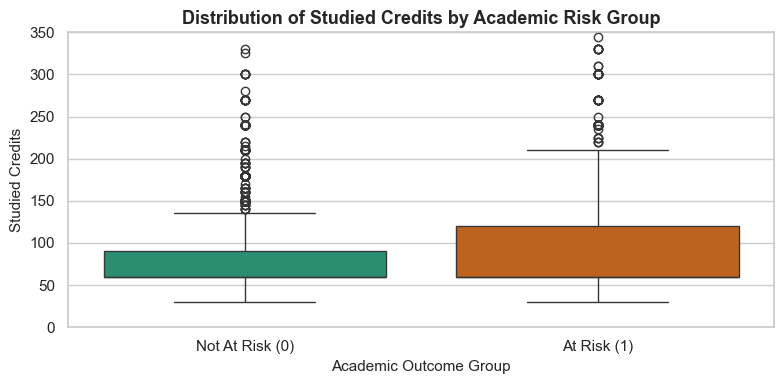

In [11]:
# Distribution of Studied Credits across Target Groups
plt.figure(figsize=(8, 4))
sns.boxplot(data=cohort, x='target', y='studied_credits', palette=['#1b9e77', '#d95f02'])
plt.xticks([0, 1], ['Not At Risk (0)', 'At Risk (1)'])
plt.title('Distribution of Studied Credits by Academic Risk Group', fontsize=13, fontweight='bold')
plt.xlabel('Academic Outcome Group', fontsize=11)
plt.ylabel('Studied Credits', fontsize=11)
plt.ylim(0, 350)
plt.tight_layout()
plt.show()


#### 4. Expected Output
Summary tables and visualizations showing:
* **Gender:** Female students have a 42.0% risk rate; Male students have a 45.3% risk rate.
* **Education:** Students with No Formal quals have the highest risk rate (60.4%), followed by Lower Than A Level (52.3%), A Level or Equivalent (39.0%), HE Qualification (35.7%), and Post Graduate Qualification (28.6%).
* **Prior Attempts:** Students with 0 prior attempts have a 41.5% risk rate, jumping to 58.5% with 1 attempt, 65.3% with 2 attempts, and over 71% with 3 attempts.
* **Disability:** Students with a declared disability experience a 53.4% risk rate compared to 42.8% for students without.
* **Studied Credits:** Students carrying higher credit loads (> 120 credits) show greater dispersion and elevated risk.

#### 5. Interpretation of Results
* **Prior educational level is a strong predictive factor:** There is an inverse relationship between entry educational qualification and subsequent academic risk.
* **Previous failures create compounding vulnerability:** Each additional prior attempt substantially increases the likelihood of subsequent failure or withdrawal.
* **Demographic factors alone cannot be treated as deterministic:** While correlations exist, demographics alone do not explain student success—dynamic engagement with course materials is critical.


---
### Section 6: VLE Engagement Analysis (Day <= 30)

#### 1. What are we doing?
We analyze student interaction with the Virtual Learning Environment (VLE) strictly on or before Day 30 (date <= 30). We calculate:
* 	otal_clicks: Total number of clicks across all resources.
* ctive_days: Number of unique days the student logged into the platform.
* unique_sites: Number of distinct learning resources visited.

We then merge these indicators into our Day 30 cohort.

#### 2. Why are we doing it?
Online interaction is the digital equivalent of classroom attendance and participation in distance education. If a student is disengaged during the first month, they fall behind on foundational concepts.


In [12]:
# Filter student_vle strictly to interactions on or before Day 30
vle_early = student_vle[student_vle['date'] <= 30]

print(f"Total VLE interaction rows on or before Day 30: {len(vle_early):,}")


Total VLE interaction rows on or before Day 30: 2,980,575


In [13]:
# Aggregate VLE indicators per student enrollment
vle_agg = vle_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    unique_sites=('id_site', 'nunique')
).reset_index()

vle_agg.head(5)


,code_module,code_presentation,id_student,total_clicks,active_days,unique_sites
0,AAA,2013J,11391,424,10,26
1,AAA,2013J,28400,618,19,34
2,AAA,2013J,30268,281,12,22
3,AAA,2013J,31604,540,24,32
4,AAA,2013J,32885,567,24,34


In [14]:
# Merge aggregated VLE indicators into the Day 30 cohort
cohort_vle = pd.merge(
    cohort,
    vle_agg,
    on=['code_module', 'code_presentation', 'id_student'],
    how='left'
)

# Identify students with 0 recorded clicks in the first 30 days
zero_click_count = cohort_vle['total_clicks'].isnull().sum()
zero_click_percent = (zero_click_count / len(cohort_vle) * 100).round(2)

print(f"Students with 0 early VLE clicks: {zero_click_count:,} ({zero_click_percent}%)")

# Compare academic risk for zero-click vs active students
zero_click_risk = cohort_vle[cohort_vle['total_clicks'].isnull()]['target'].mean() * 100
active_click_risk = cohort_vle[cohort_vle['total_clicks'].notnull()]['target'].mean() * 100

print(f"Academic Risk Rate for Zero-Click Students: {zero_click_risk:.2f}%")
print(f"Academic Risk Rate for Active-Click Students: {active_click_risk:.2f}%")


Students with 0 early VLE clicks: 836 (3.05%)
Academic Risk Rate for Zero-Click Students: 81.82%
Academic Risk Rate for Active-Click Students: 42.60%


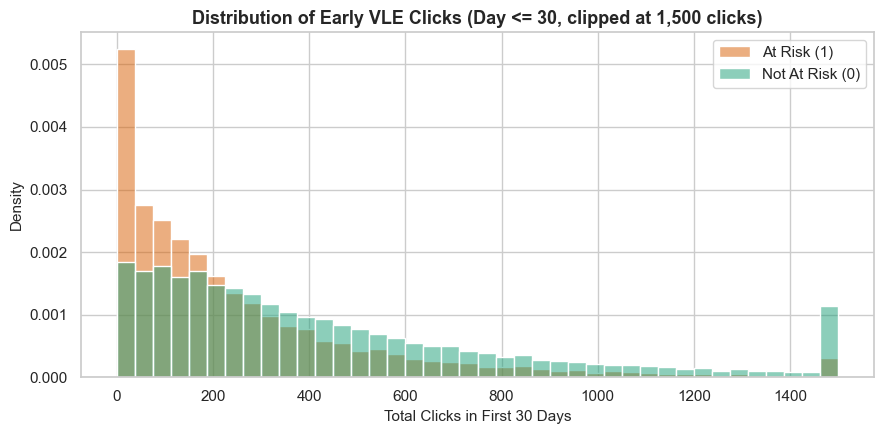

In [15]:
# Distribution of Total Early Clicks by Academic Risk
plt.figure(figsize=(9, 4.5))
# Use log scale visualization or 95th percentile clipping to handle positive skew
clipped_clicks = cohort_vle['total_clicks'].fillna(0).clip(upper=1500)
sns.histplot(data=cohort_vle, x=clipped_clicks, hue='target', bins=40, palette=['#1b9e77', '#d95f02'], common_norm=False, stat='density')
plt.title('Distribution of Early VLE Clicks (Day <= 30, clipped at 1,500 clicks)', fontsize=13, fontweight='bold')
plt.xlabel('Total Clicks in First 30 Days', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.legend(['At Risk (1)', 'Not At Risk (0)'])
plt.tight_layout()
plt.show()


C:\Users\vhres\AppData\Local\Temp\ipykernel_28124\3625041001.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cohort_vle, x='target', y='active_days', palette=['#1b9e77', '#d95f02'])


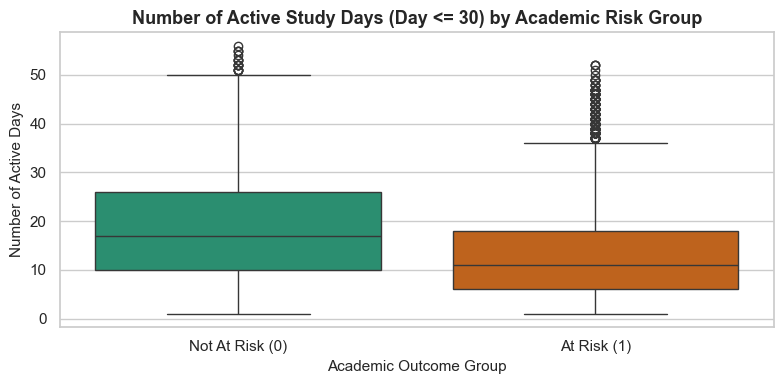

In [16]:
# Boxplot: Active Days on or before Day 30 by Target Class
plt.figure(figsize=(8, 4))
sns.boxplot(data=cohort_vle, x='target', y='active_days', palette=['#1b9e77', '#d95f02'])
plt.xticks([0, 1], ['Not At Risk (0)', 'At Risk (1)'])
plt.title('Number of Active Study Days (Day <= 30) by Academic Risk Group', fontsize=13, fontweight='bold')
plt.xlabel('Academic Outcome Group', fontsize=11)
plt.ylabel('Number of Active Days', fontsize=11)
plt.tight_layout()
plt.show()


#### 4. Expected Output
* 2,980,575 early VLE interaction rows.
* **836 students (3.05%)** in the Day 30 cohort logged **0 clicks** during the first 30 days.
* **Zero-click risk rate:** **81.82%** of zero-click students subsequently failed or withdrew!
* **Active-click risk rate:** 42.60%.
* **Distribution difference:** Not At Risk students have a median of 320 clicks and 17 active days; At Risk students have a median of 175 clicks and 11 active days.

#### 5. Interpretation of Results
* **Early digital disengagement is an immediate warning indicator:** Over 8 out of 10 students with 0 clicks by Day 30 fail or drop out.
* **Regularity of study matters:** Successful students log in on twice as many individual days as at-risk students, showing that consistent study habits strongly associate with course completion.


---
### Section 7: Early Assessment Analysis (Submission Date <= 30)

#### 1. What are we doing?
We analyze student assessment submissions completed strictly on or before Day 30 (date_submitted <= 30). We calculate:
* early_assessments_submitted: The count of early assessments submitted by the student.
* early_avg_score: The mean score achieved on early submissions.

#### 2. Why are we doing it?
Submitting the first assignment is a major milestone in university courses. An early submission demonstrates active study, and the score provides direct feedback on academic comprehension.


In [17]:
# Merge student assessment submissions with assessment metadata
sa_merged = pd.merge(student_assessment, assessments, on='id_assessment', how='left')

# Keep only submissions made on or before Day 30
sa_early = sa_merged[sa_merged['date_submitted'] <= 30]

print(f"Total assessment submissions on or before Day 30: {len(sa_early):,}")


Total assessment submissions on or before Day 30: 26,522


In [18]:
# Aggregate early assessment performance per student enrollment
sa_agg = sa_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    early_assessments_submitted=('id_assessment', 'count'),
    early_avg_score=('score', 'mean')
).reset_index()

sa_agg.head(5)


,code_module,code_presentation,id_student,early_assessments_submitted,early_avg_score
0,AAA,2013J,11391,1,78.0
1,AAA,2013J,28400,1,70.0
2,AAA,2013J,31604,1,72.0
3,AAA,2013J,32885,1,69.0
4,AAA,2013J,38053,1,79.0


In [19]:
# Merge early assessment metrics into our cohort
cohort_all = pd.merge(
    cohort_vle,
    sa_agg,
    on=['code_module', 'code_presentation', 'id_student'],
    how='left'
)

# Check submission volume
submitted_count = cohort_all['early_assessments_submitted'].notnull().sum()
no_submission_count = cohort_all['early_assessments_submitted'].isnull().sum()

print(f"Students with at least one early submission (Day <= 30): {submitted_count:,} ({submitted_count / len(cohort_all) * 100:.1f}%)")
print(f"Students with NO early submission: {no_submission_count:,} ({no_submission_count / len(cohort_all) * 100:.1f}%)")

# Compare risk rate for students with early submissions vs no early submission
early_sub_risk = cohort_all[cohort_all['early_assessments_submitted'].notnull()]['target'].mean() * 100
no_sub_risk = cohort_all[cohort_all['early_assessments_submitted'].isnull()]['target'].mean() * 100

print(f"Academic Risk Rate for students with early submission: {early_sub_risk:.2f}%")
print(f"Academic Risk Rate for students with NO early submission: {no_sub_risk:.2f}%")


Students with at least one early submission (Day <= 30): 20,832 (76.1%)
Students with NO early submission: 6,541 (23.9%)
Academic Risk Rate for students with early submission: 39.80%
Academic Risk Rate for students with NO early submission: 56.51%


C:\Users\vhres\AppData\Local\Temp\ipykernel_28124\1236069436.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cohort_all, x='target', y='early_avg_score', palette=['#1b9e77', '#d95f02'])


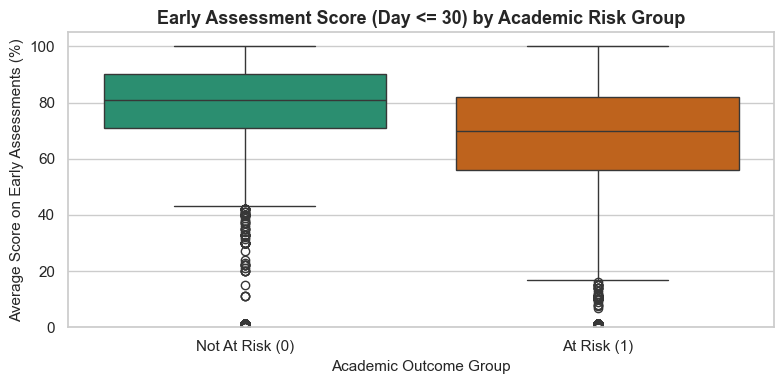

In [20]:
# Distribution of Early Assessment Scores by Academic Risk Group
plt.figure(figsize=(8, 4))
sns.boxplot(data=cohort_all, x='target', y='early_avg_score', palette=['#1b9e77', '#d95f02'])
plt.xticks([0, 1], ['Not At Risk (0)', 'At Risk (1)'])
plt.title('Early Assessment Score (Day <= 30) by Academic Risk Group', fontsize=13, fontweight='bold')
plt.xlabel('Academic Outcome Group', fontsize=11)
plt.ylabel('Average Score on Early Assessments (%)', fontsize=11)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


#### 4. Expected Output
* 26,522 early assessment submission records.
* **20,832 students (76.1%)** in the Day 30 cohort submitted at least one assignment on or before Day 30.
* **6,541 students (23.9%)** had no early submission on or before Day 30 (either because their module's first assignment was scheduled after Day 30, or because the student did not submit).
* **Risk rate without early submission:** **56.51%**.
* **Risk rate with early submission:** **39.80%**.
* **Score differences:** Successful students averaged 77.8% (median 81.0%), while at-risk students averaged 66.7% (median 70.0%).

#### 5. Interpretation of Results
* Submitting early assignments is strongly protective: submitting early reduces risk by nearly 17 percentage points.
* Early academic marks provide a clear signal: students scoring below 60 on initial assignments face elevated risk of eventual failure or withdrawal.


---
### Section 8: Relationship Between Engagement and Academic Risk

#### 1. What are we doing?
We synthesize our demographic, engagement, and assessment metrics to compare median and mean values across both target groups.

#### 2. Why are we doing it?
To summarize and rank the key predictive indicators that differentiate At Risk students from Not At Risk students before entering preprocessing and model training.


In [21]:
# Statistical summary comparing At Risk vs Not At Risk students
# Simple statistical summary comparing At Risk vs Not At Risk students
comparison_table = pd.DataFrame({
    'Not At Risk (0)': [
        cohort_all[cohort_all['target'] == 0]['total_clicks'].median(),
        cohort_all[cohort_all['target'] == 0]['total_clicks'].mean().round(1),
        cohort_all[cohort_all['target'] == 0]['active_days'].median(),
        cohort_all[cohort_all['target'] == 0]['early_avg_score'].mean().round(1),
        cohort_all[cohort_all['target'] == 0]['num_of_prev_attempts'].mean().round(2),
        cohort_all[cohort_all['target'] == 0]['studied_credits'].mean().round(1)
    ],
    'At Risk (1)': [
        cohort_all[cohort_all['target'] == 1]['total_clicks'].median(),
        cohort_all[cohort_all['target'] == 1]['total_clicks'].mean().round(1),
        cohort_all[cohort_all['target'] == 1]['active_days'].median(),
        cohort_all[cohort_all['target'] == 1]['early_avg_score'].mean().round(1),
        cohort_all[cohort_all['target'] == 1]['num_of_prev_attempts'].mean().round(2),
        cohort_all[cohort_all['target'] == 1]['studied_credits'].mean().round(1)
    ]
}, index=[
    'Median Early Clicks', 
    'Mean Early Clicks', 
    'Median Active Days', 
    'Mean Early Score (%)', 
    'Mean Prior Attempts', 
    'Mean Studied Credits'
])

comparison_table


,Not At Risk (0),At Risk (1)
Median Early Clicks,320.00,175.00
Mean Early Clicks,467.70,279.20
Median Active Days,17.00,11.00
Mean Early Score (%),77.80,66.70
Mean Prior Attempts,0.11,0.22
Mean Studied Credits,73.70,79.50


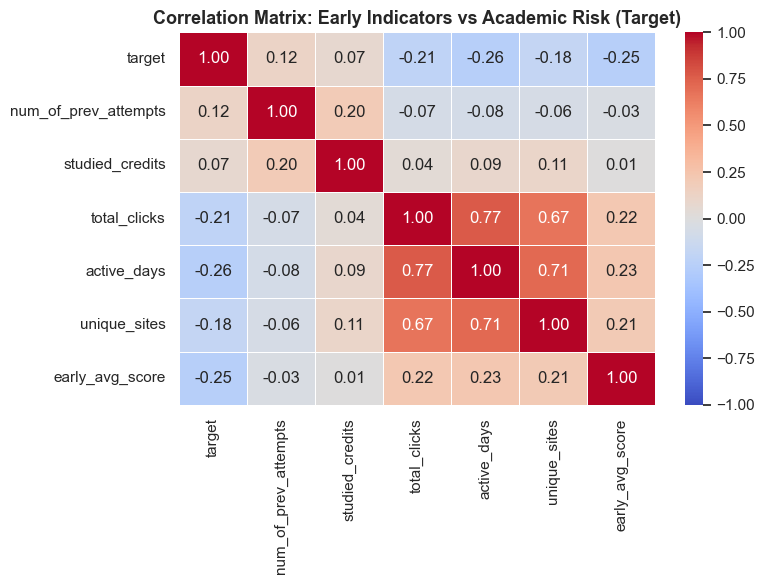

In [22]:
# Correlation matrix between numerical early indicators and target
num_cols = ['target', 'num_of_prev_attempts', 'studied_credits', 'total_clicks', 'active_days', 'unique_sites', 'early_avg_score']
corr_matrix = cohort_all[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix: Early Indicators vs Academic Risk (Target)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


#### 4. Expected Output
A summary comparison table and correlation heatmap showing:
* 	otal_clicks and ctive_days have moderate negative correlations with 	arget (higher engagement = lower risk).
* early_avg_score has a negative correlation with 	arget (higher scores = lower risk).
* 
um_of_prev_attempts has a positive correlation with 	arget (more attempts = higher risk).

#### 5. Interpretation of Results & Correlation vs. Causation
* **Key Signals:** Early VLE clicks, active study days, and early assessment marks provide the strongest signals for identifying at-risk students.
* **Important Note on Causation:** A high number of clicks does not automatically cause a student to pass; clicking represents active studying, reading course materials, and engaging with learning activities. Predictive models capture these behavioral correlations to assist teachers, not to imply that clicking alone guarantees academic mastery.


---
### Section 9: Missing Values and Important Observations

#### 1. What are we doing?
We audit missing values in our Day 30 cohort DataFrame and document how they must be addressed in Notebook 03 (Data Preprocessing).

#### 2. Why are we doing it?
Machine learning algorithms (such as Logistic Regression, KNN, and Random Forest) cannot process raw NaN values. Understanding the origin of each missing value allows us to choose appropriate, domain-sound imputation methods during preprocessing.


In [23]:
# Check missing values across all variables in the consolidated cohort
missing_counts = cohort_all.isnull().sum()
missing_percents = (missing_counts / len(cohort_all) * 100).round(2)

missing_audit = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing (%)': missing_percents
})

# Filter only columns with missing values
missing_audit = missing_audit[missing_audit['Missing Count'] > 0]
missing_audit


,Missing Count,Missing (%)
imd_band,1026,3.75
date_registration,7,0.03
date_unregistration,22428,81.93
total_clicks,836,3.05
active_days,836,3.05
unique_sites,836,3.05
early_assessments_submitted,6541,23.90
early_avg_score,6546,23.91


#### 4. Expected Output
A table detailing missing values in:
* date_unregistration: 22,428 missing (expected: completing students).
* imd_band: 1,026 missing (3.75%) in the Day 30 cohort.
* date_registration: 7 missing (0.03%).
* 	otal_clicks, ctive_days, unique_sites: 836 missing (3.05%).
* early_assessments_submitted: 6,541 missing (23.90%).
* early_avg_score: 6,541 missing (23.90%).

#### 5. Interpretation of Results and Preprocessing Plan
1. **Engagement Metrics (	otal_clicks, ctive_days, unique_sites):**
   * Missing values occur because students with 0 clicks in the first 30 days had no rows in studentVle.
   * **Preprocessing Solution:** Impute with **0** (reflecting zero activity).
2. **Early Assessments (early_assessments_submitted):**
   * Missing values mean 0 assignments were submitted $\le$ Day 30.
   * **Preprocessing Solution:** Impute submission count with **0**.
3. **Early Assessment Scores (early_avg_score):**
   * Students with no early submissions do not have a test score.
   * **Preprocessing Solution:** Create a binary indicator feature (has_early_submission), and impute score with median or a dedicated flag (0 or neutral value) so the model distinguishes between low scores and unsubmitted assignments.
4. **imd_band:**
   * Missing for 3.76% of students due to unrecorded postcode.
   * **Preprocessing Solution:** Impute with 'Missing' category or mode during categorical encoding.


---
### Section 10: EDA Summary and Next Steps

#### Summary of Key Findings from EDA
1. **Cohort & Target Distribution:**
   * Exactly **27,373 active students** on Day 30.
   * Target balance: **56.21% Not At Risk** vs **43.79% At Risk**.
2. **Demographics:**
   * Lower prior educational qualifications and multiple prior attempts correlate with elevated academic risk.
   * Declared disability shows an increased risk rate (53.4% vs 42.8%).
3. **Early Online Engagement:**
   * Students with 0 clicks by Day 30 have an **81.82% risk rate**.
   * Successful students log in on twice as many days (median 17 vs 11 days) and generate nearly double the clicks.
4. **Early Academic Performance:**
   * Submitting an early assignment reduces risk by 17 percentage points.
   * Students scoring below 60 on initial assignments have significantly higher rates of subsequent failure.
5. **Zero Data Leakage Maintained:**
   * All predictive indicators analyzed strictly use information generated **on or before Day 30**. Future assessment grades and post-Day 30 VLE interactions were completely excluded.

#### Limitations of the Analysis
* Online clicks reflect digital interaction, which is a proxy for study effort in distance learning, but does not measure study depth, comprehension, or external life circumstances.
* Some courses do not schedule an assessment within the first 30 days, making assessment features course-dependent.

#### Next Steps: Notebook 03 (Data Preprocessing & Feature Engineering)
In **Notebook 03**, we will:
* Clean and impute missing values according to our preprocessing plan.
* Engineer clean, leakage-free student-level features up to Day 30.
* Encode categorical variables (gender, education, ge_band, disability, imd_band).
* Implement a **group-aware train/test split on id_student** to prevent student-level data leakage.
* Save the clean processed modeling dataset to data/processed/oulad_early_risk_day30.csv.
